## Business Task: Analayze the data from Fitbit users to identify the trends of the smart device usage. The insights will guide Bellabeat's marketing strategy for their line of smart wellness products.

1. Identify trends in the device usage.
2. How do these trends apply to Bellabeat customers.
3. How can these trends improve Bellabeat's marketing strategy.

I used the FitBit fitness tracker data, available on Kaggle. It contains fitness tracked data from 30 users/customers.
-It's reliability is very low, since its only from 30 users (low data).
-Originally Amazon Mechanical Turk (third-party data).
-It is a bit hard to comprehend the data since it contains heart rates, sleep and steps.
-Its not current. The data was taken back in 2016 so it does not include current post-pandemic habits.
-It is well documented.

I used BigQuery to efficiently join large data sets and ensure data integrity. I deleted 3 duplicated rows on Goggle Sheets, standarized the dates to YYYY-MM-DD to avoid SQL issues. Joined Daily Activity with Sleep Data with INNER JOIN on Id and Date.
SQL:

'''SELECT 
    A.Id,
    A.ActivityDate,
    A.SedentaryMinutes,
    S.TotalMinutesAsleep,
    S.TotalTimeInBed
FROM 
    `bellabeatproject-488620.bellabeat_data.daily_activity` AS A
INNER JOIN 
    `bellabeatproject-488620.bellabeat_data.sleep_day` AS S
    ON A.Id = S.Id 
    AND A.ActivityDate = CAST(S.SleepDay AS DATE)
WHERE 
    S.TotalMinutesAsleep > 0 
    AND A.SedentaryMinutes > 0;
'''SELECT 
    CASE 
        WHEN SedentaryMinutes > 720 THEN 'High Sedentary (12h+)'
        WHEN SedentaryMinutes BETWEEN 480 AND 720 THEN 'Moderate Sedentary (8-12h)'
        ELSE 'Low Sedentary (<8h)' 
    END AS sedentary_level,
    ROUND(AVG(TotalMinutesAsleep), 2) AS avg_minutes_asleep,
    COUNT(*) AS total_logs
FROM (
    SELECT A.SedentaryMinutes, S.TotalMinutesAsleep
    FROM `bellabeatproject-488620.bellabeat_data.daily_activity` AS A
    JOIN `bellabeatproject-488620.bellabeat_data.sleep_day` AS S
    ON A.Id = S.Id AND A.ActivityDate = CAST(S.SleepDay AS DATE)
)
GROUP BY sedentary_level;
'''

I then exported the data to Tableau to view the relationships between activity labels and sleep quality. There I found 2 discoveries:
1. A negative correlation bewteen sedentary time and sleep time. When users spend more time inactive during the day, their sleep time decreases.
2. There is a lack of sleep during the middle of the week, specially Tuesday and Thursday. While the highest average sleep is on Sunday and Wednesday.
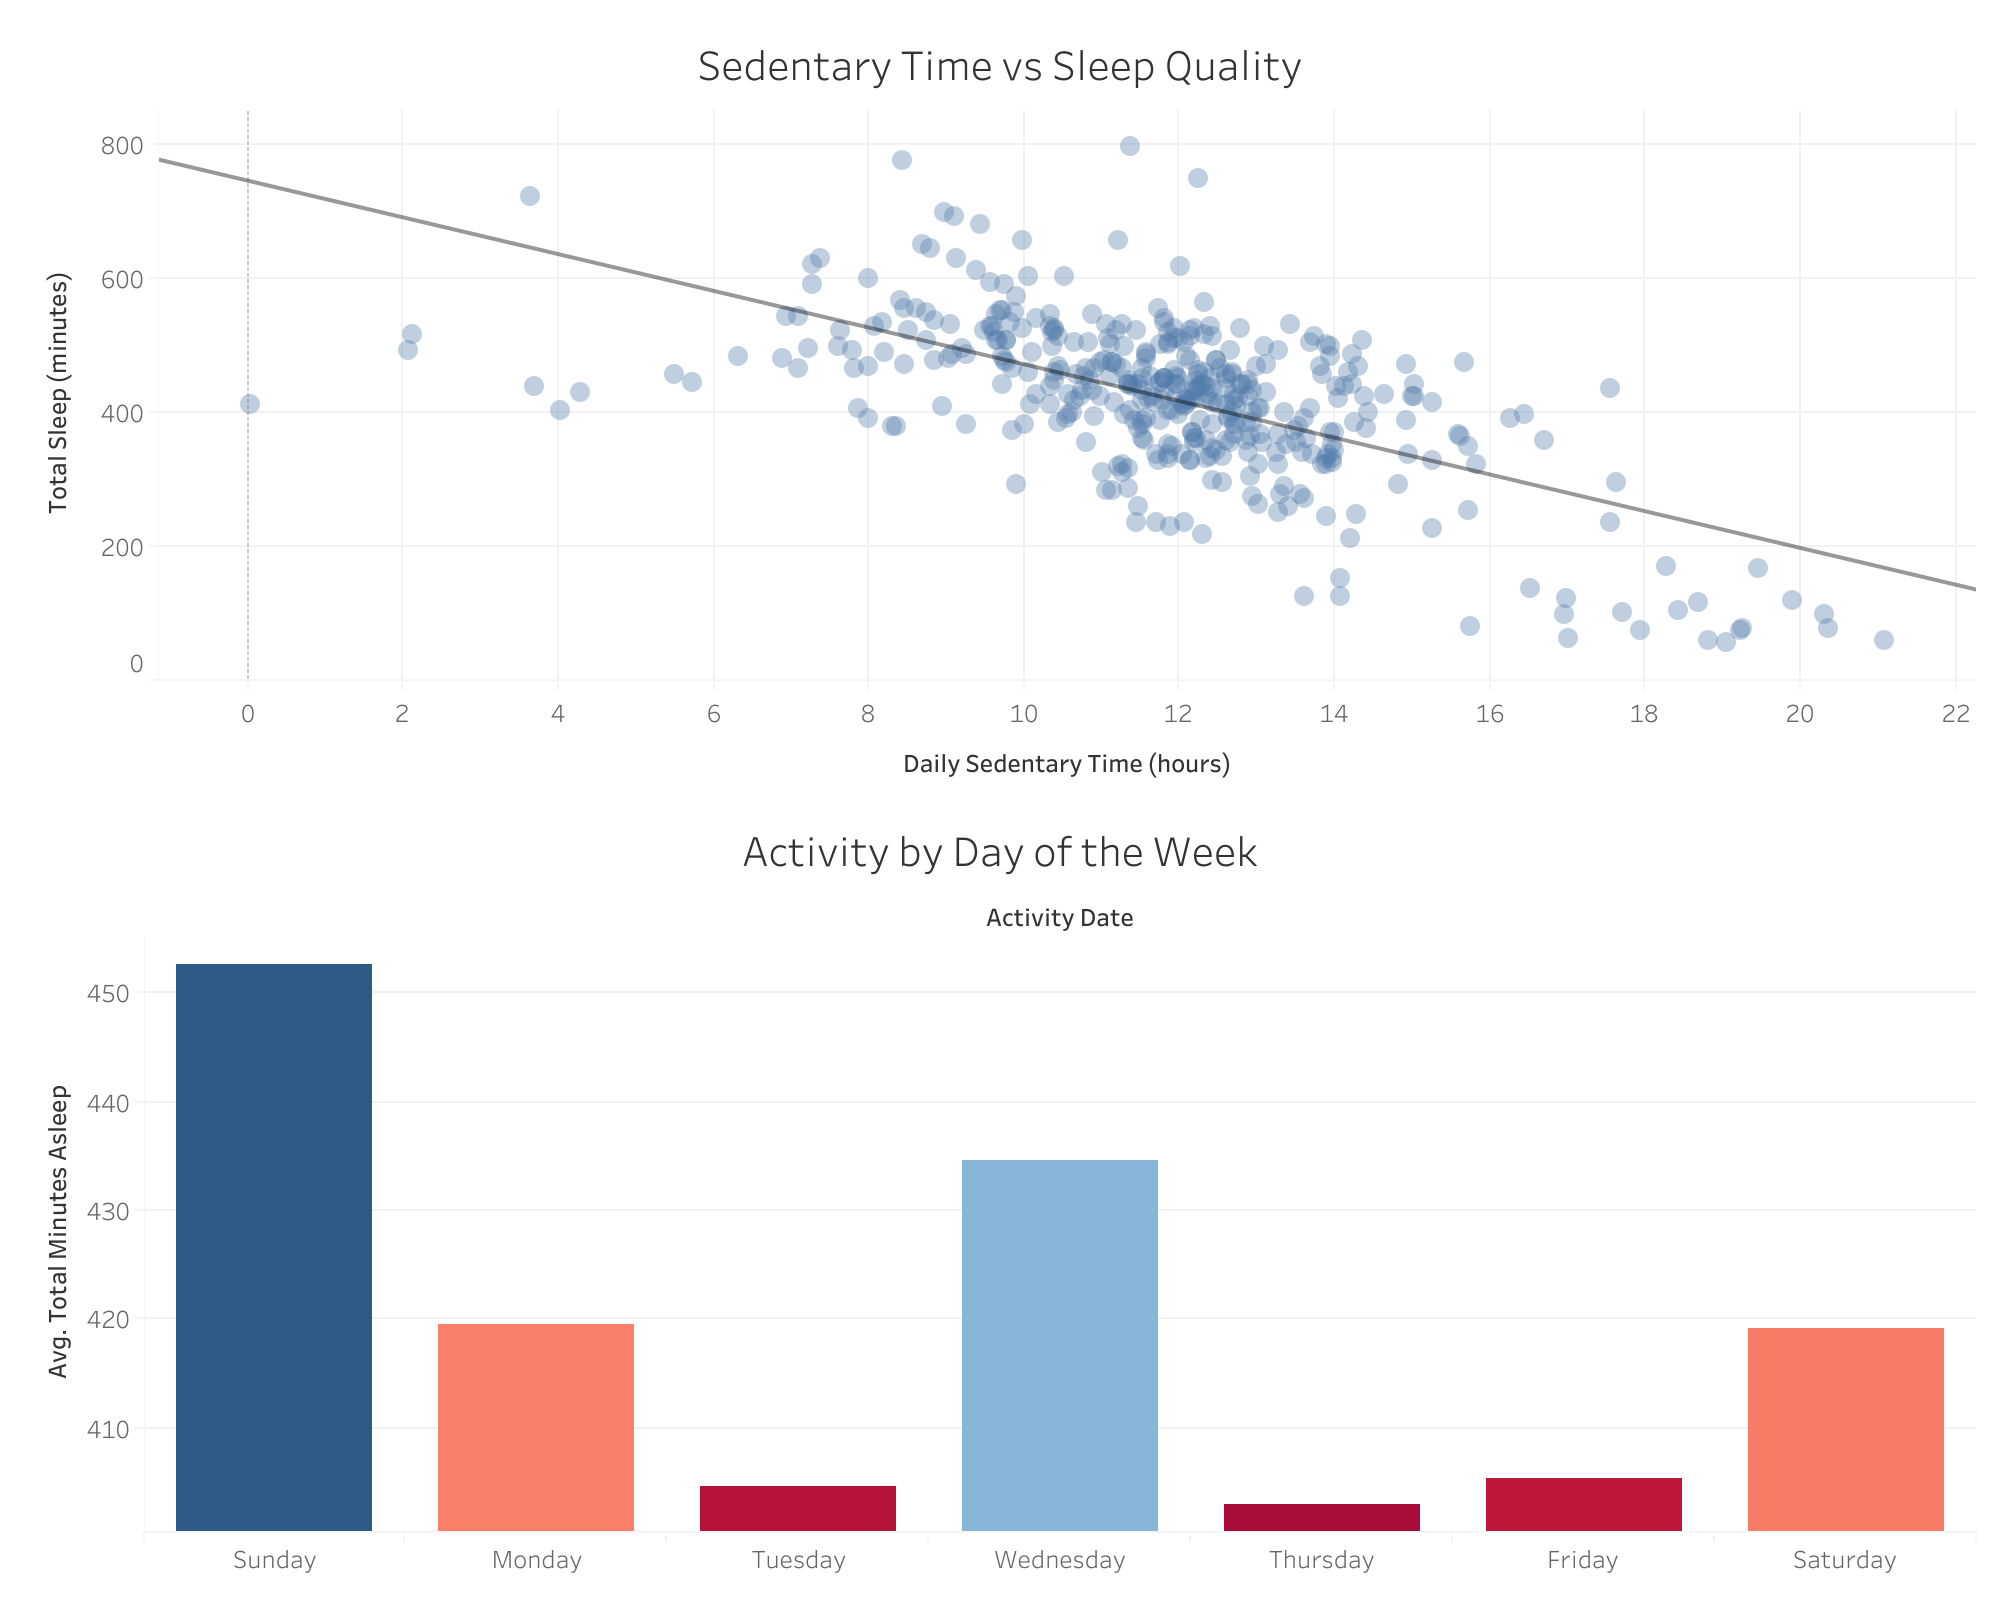

With these results and trends, my 3 recommendations are:
1. Sedentary Alerts: Implement an app feature that tracks sedentary time. If the user passes 10 hours of inactivity, the app suggests a little 10-15 movement before bed to improve sleep time.
2. Mid Week Motivation: Launch a "Mid week Refresh" campaign starting on Tuesdays, which could include push notifications with some relaxing advice such as meditation or breathing excercises ot improve the decrease in sleep during this period.
3. Personalized Goal Setting: Use the products to help the users visualize how their activity during the daytime impacts on their sleep time, encouraging changes in daily rutines.


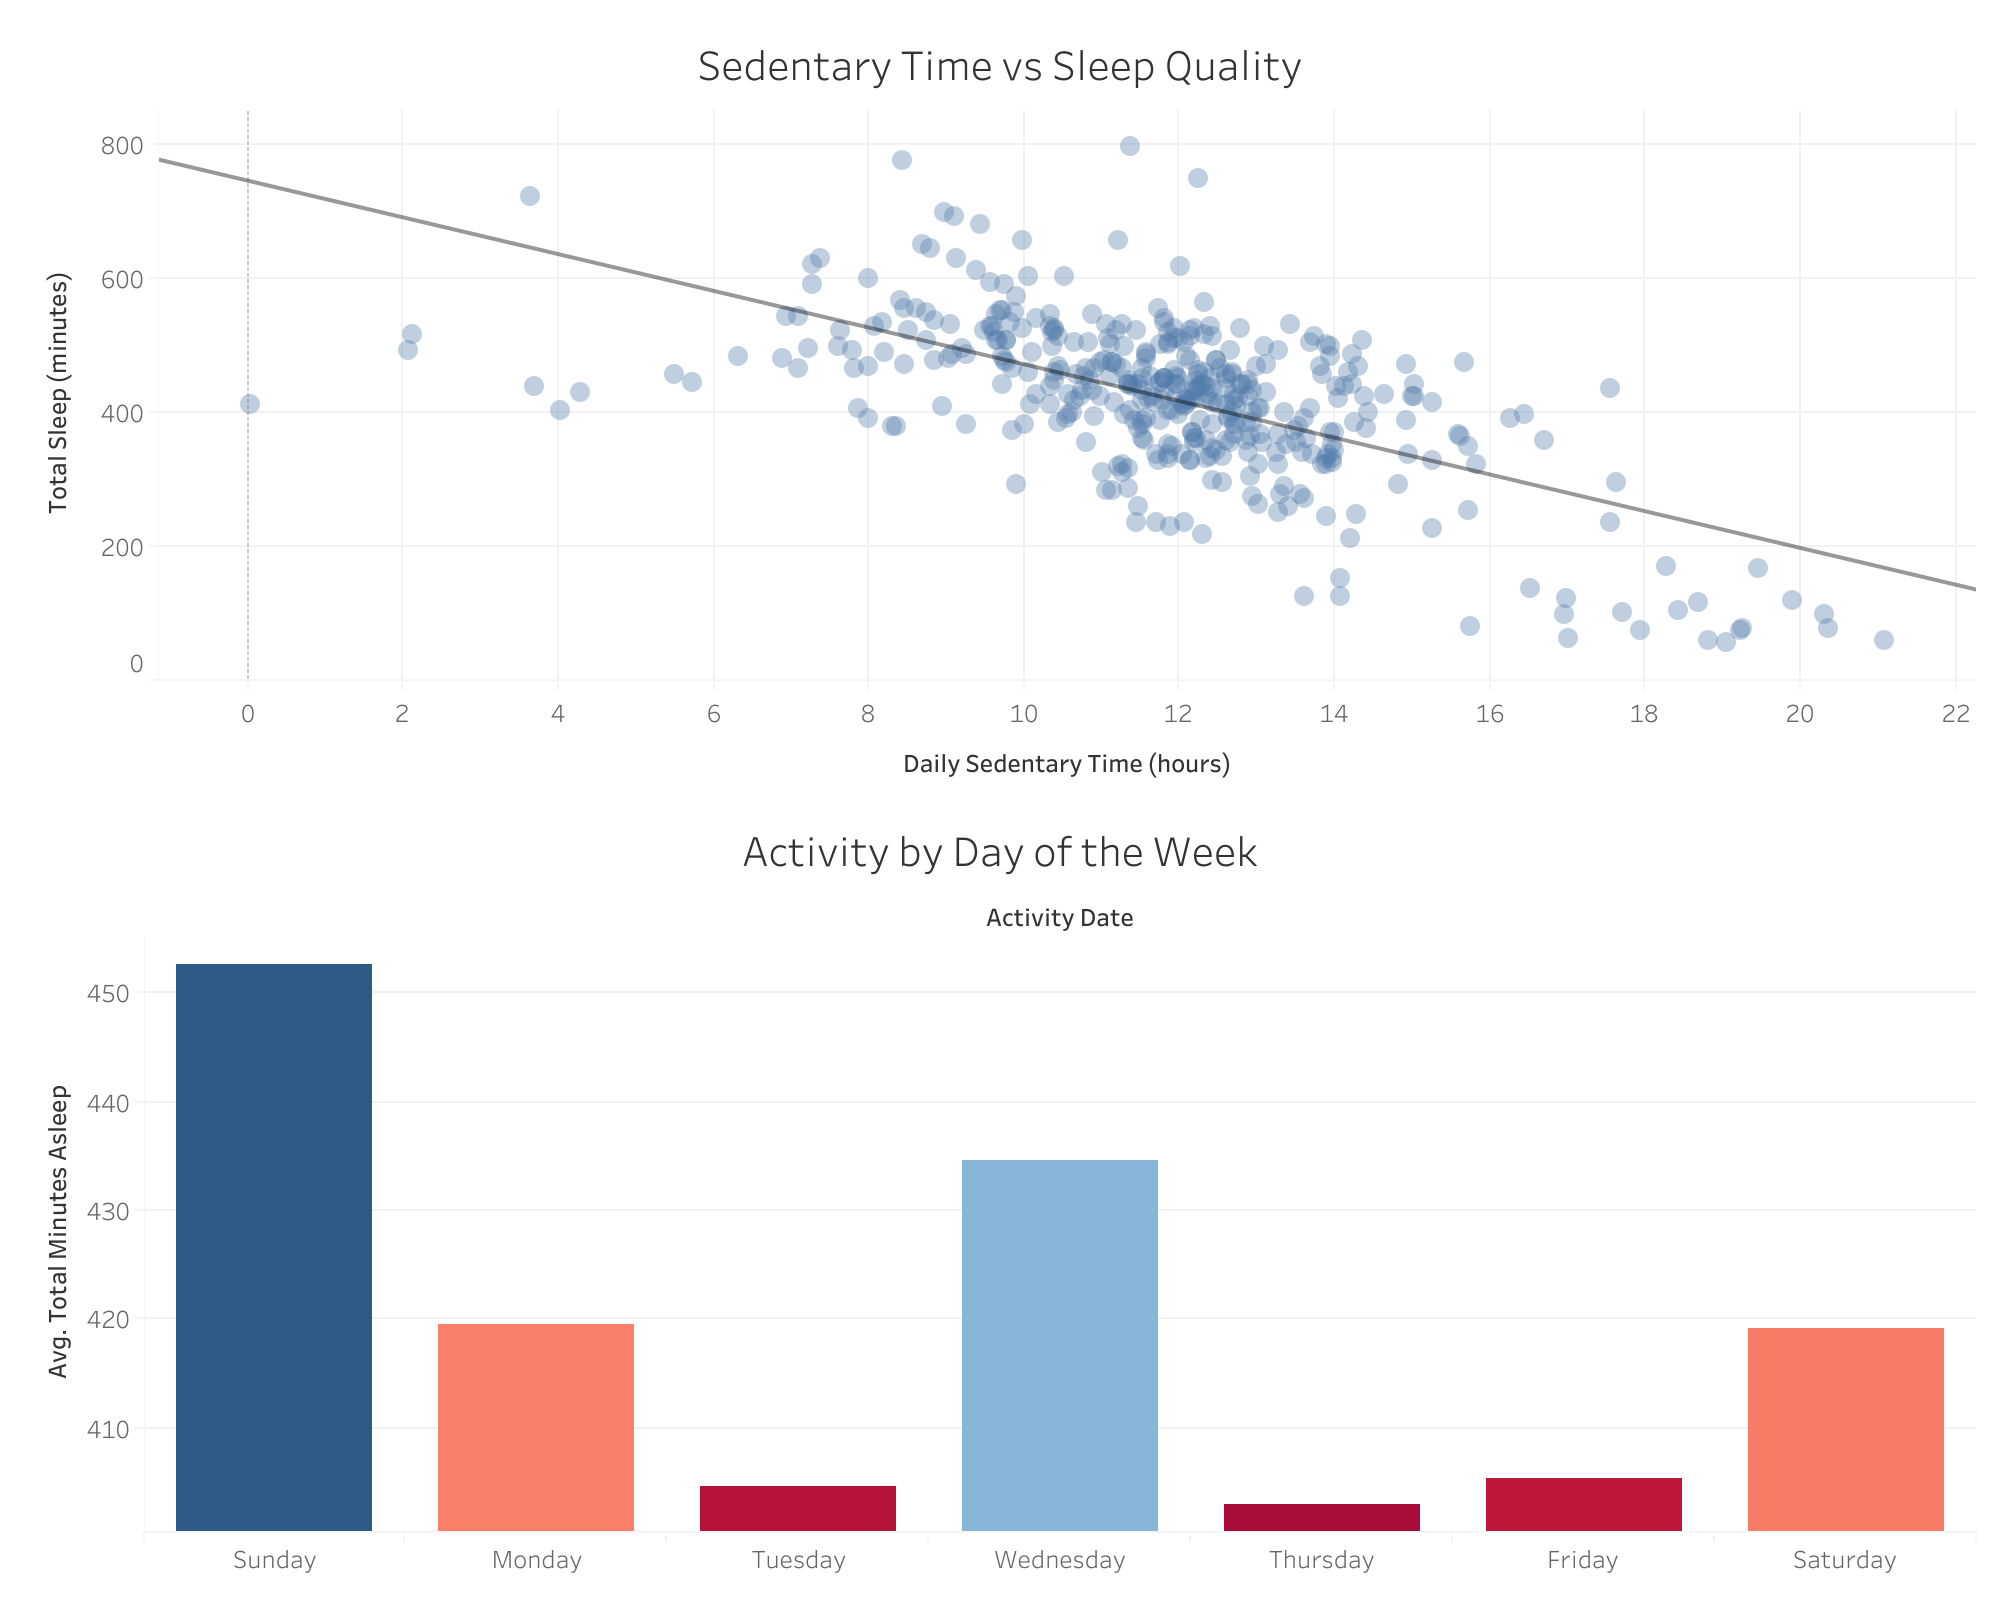
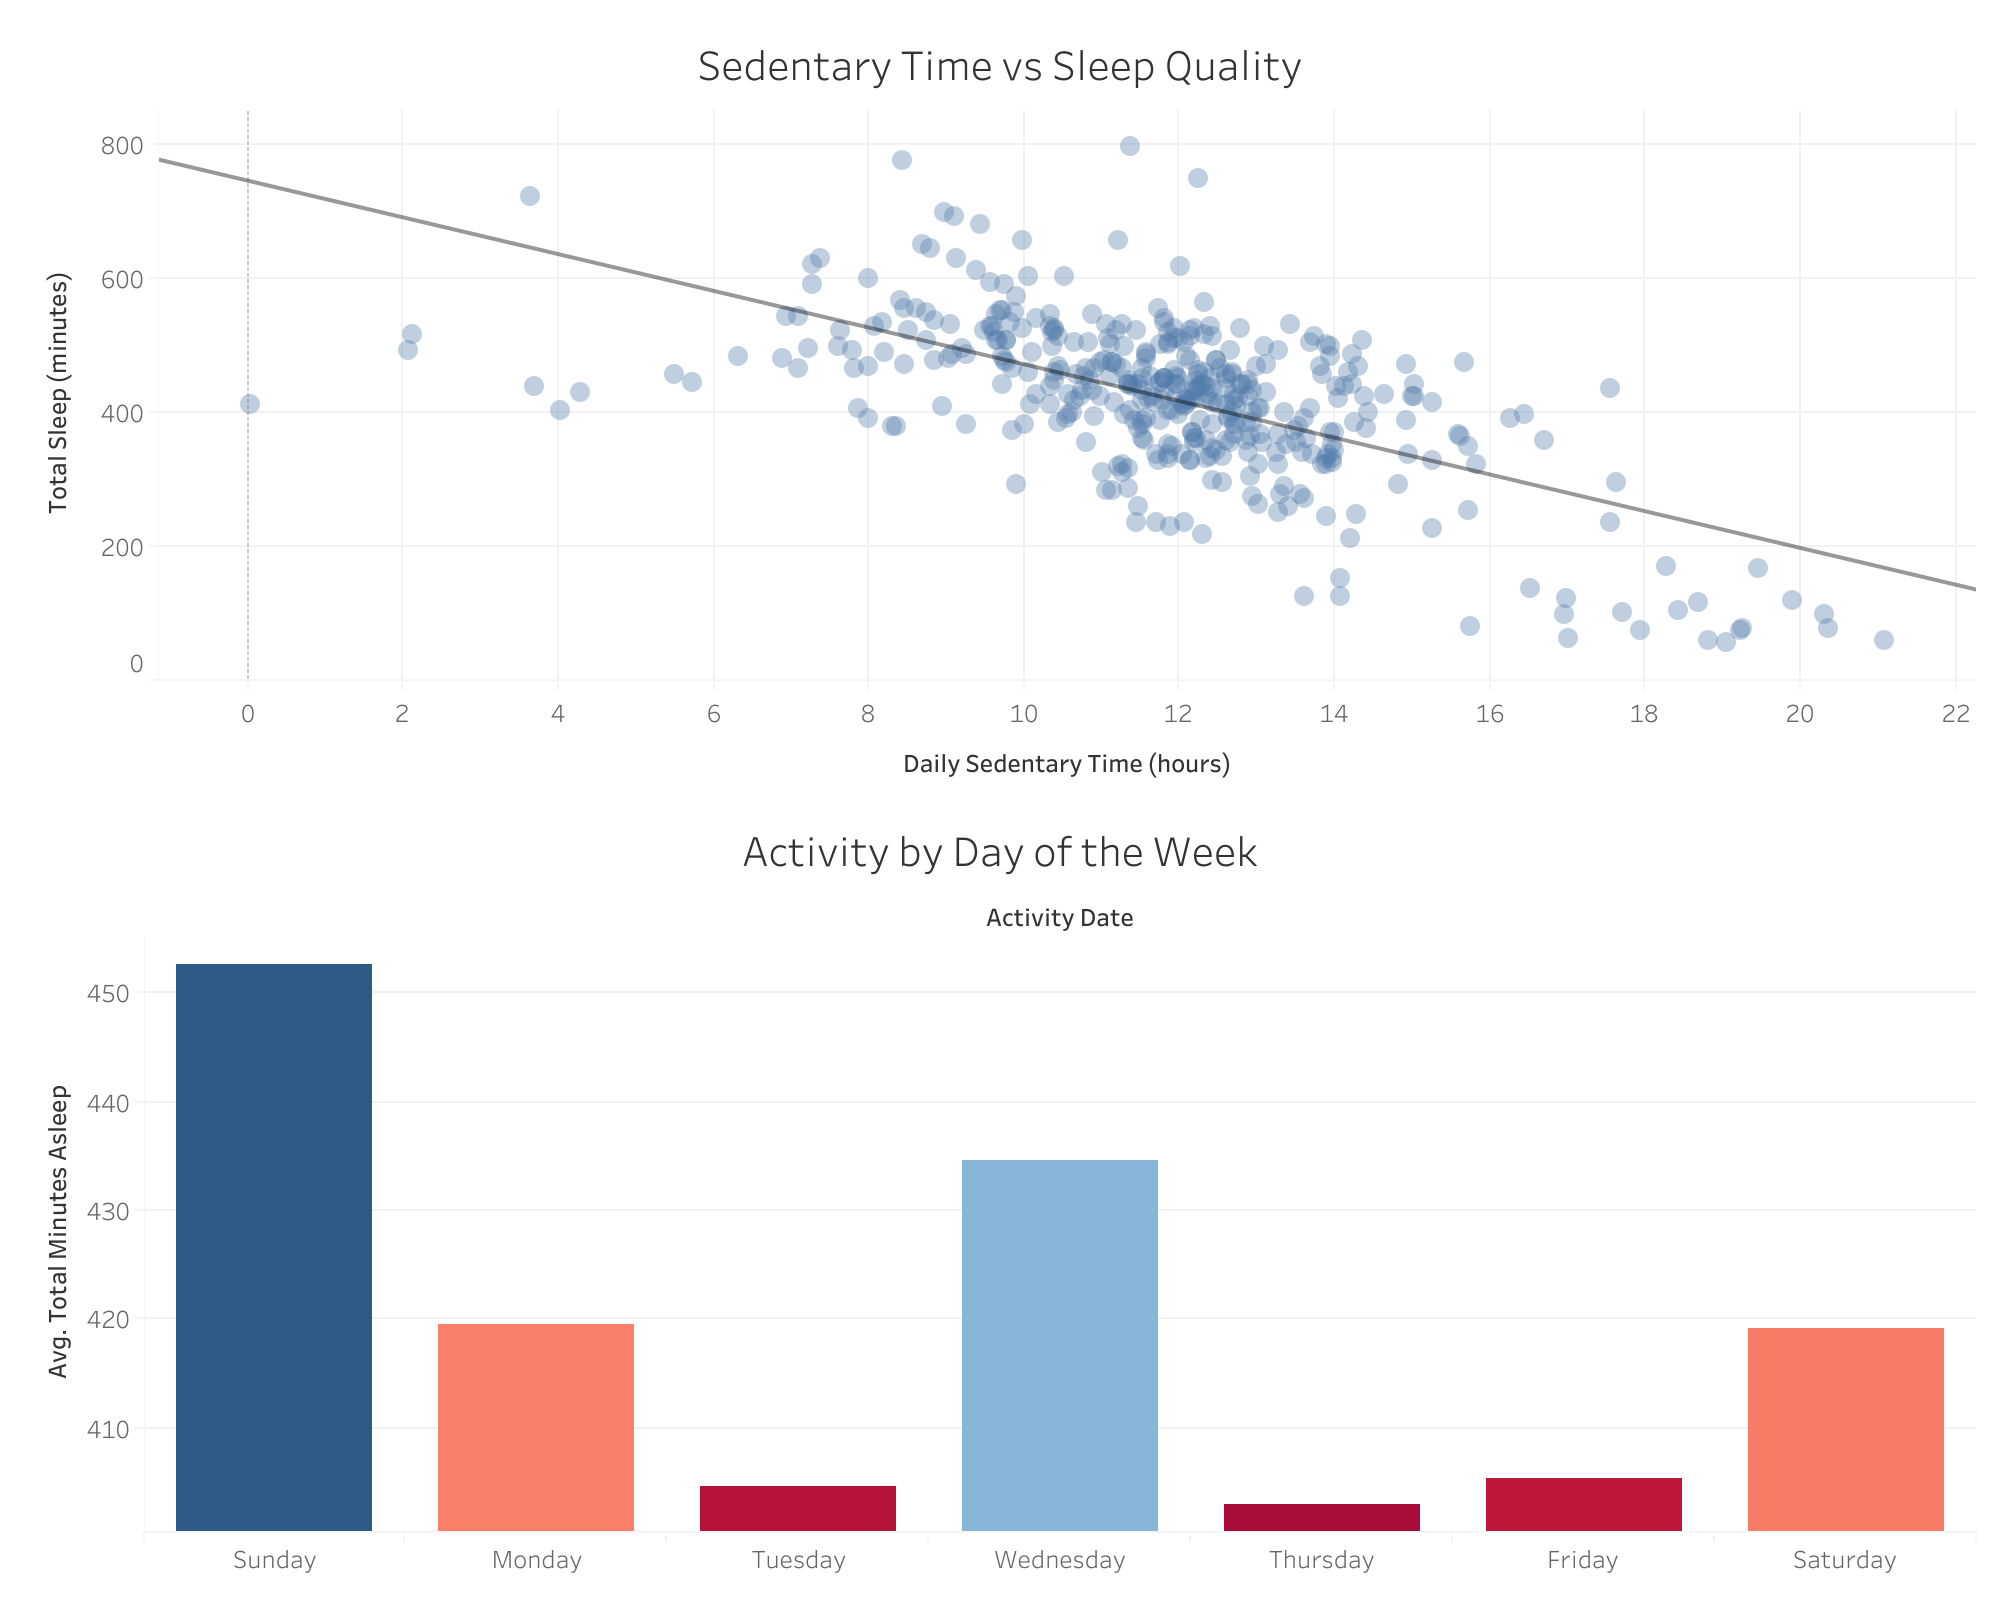